# Лабораторная работа № 1. Линейная регрессия

**Дисциплина:** Системы искусственного интеллекта и машинное обучение  
**Группа:** АВТ-342  
**Новосибирск, 2026**

## Цель работы

Получить практические навыки первичного анализа исходных данных, подготовки таблицы к обработке, изучения взаимосвязей между признаками и построения линейных регрессионных моделей на языке Python.

## Исходные данные

Набор Seoul Bike Sharing Demand содержит почасовые сведения о количестве арендованных велосипедов в Сеуле и погодных условиях. Период наблюдений — с 1 декабря 2017 года по 30 ноября 2018 года.

| Признак | Содержание |
|---|---|
| Date, Hour | Дата и час наблюдения |
| Rented Bike Count | Количество аренд за час |
| Temperature(°K) | Температура воздуха, K |
| Humidity(%) | Относительная влажность, % |
| Wind speed (m-s) | Скорость ветра, м/с |
| Visibility (10m) | Видимость, десятки метров |
| Dew point temperature(°K) | Температура точки росы, K |
| Solar Radiation (MJ-m2) | Солнечная радиация, МДж/м² |
| Rainfall(mm), Snowfall (cm) | Количество дождевых и снежных осадков |
| Seasons | Сезон |
| Holiday | Признак праздничного дня |
| Functioning Day | Признак работы системы проката |

Исходный файл представлен в формате CSV с разделителем `#`, десятичной точкой и заголовками столбцов.

## 1. Первичный анализ данных

### 1.1. Подключение библиотек

In [1]:
import pandas as pd
import numpy as np
import sklearn
from sklearn import linear_model, metrics
from sklearn.model_selection import train_test_split
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

### 1.2. Загрузка входных данных

In [2]:
df = pd.read_csv(
    'SeoulBikeData_nan24_SIIiMO.csv',
    sep='#',
    decimal='.',
    header=0,
    index_col=0
)
display(df.head(10))

,Date,Rented Bike Count,Hour,Temperature(°K),Humidity(%),Wind speed (m-s),Visibility (10m),Dew point temperature(°K),Solar Radiation (MJ-m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01-12-2017,254.0,0.0,267.95,37.0,2.2,2000.0,255.55,0.00,0.0,0.0,Winter,No Holiday,Yes
1,01-12-2017,204.0,1.0,267.65,38.0,0.8,2000.0,255.55,0.00,0.0,0.0,Winter,No Holiday,Yes
2,01-12-2017,173.0,2.0,267.15,39.0,1.0,2000.0,255.45,0.00,0.0,0.0,Winter,No Holiday,Yes
3,01-12-2017,107.0,3.0,266.95,40.0,0.9,2000.0,255.55,0.00,0.0,0.0,Winter,No Holiday,Yes
4,01-12-2017,78.0,4.0,267.15,36.0,2.3,2000.0,254.55,0.00,0.0,0.0,Winter,No Holiday,Yes
5,01-12-2017,100.0,5.0,266.75,37.0,1.5,2000.0,254.45,0.00,0.0,0.0,Winter,No Holiday,Yes
6,01-12-2017,181.0,6.0,266.54999999999995,35.0,1.3,2000.0,253.65,0.00,0.0,0.0,Winter,No Holiday,Yes
7,01-12-2017,460.0,7.0,265.75,38.0,0.9,2000.0,253.85,0.00,0.0,0.0,Winter,No Holiday,Yes
8,01-12-2017,930.0,8.0,265.54999999999995,37.0,1.1,2000.0,253.35,0.01,0.0,0.0,Winter,No Holiday,Yes
9,01-12-2017,490.0,9.0,266.65,27.0,0.5,1928.0,250.75,0.23,0.0,0.0,Winter,No Holiday,Yes


### 1.3. Размер, типы и статистические характеристики

In [3]:
print(df.shape)
print(f'Итого: {df.shape[0]} записей, {df.shape[1]} столбцов')
df.info()

(8760, 14)
Итого: 8760 записей, 14 столбцов
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8758 non-null   str    
 1   Rented Bike Count          8759 non-null   str    
 2   Hour                       8758 non-null   str    
 3   Temperature(°K)            8758 non-null   str    
 4   Humidity(%)                8758 non-null   float64
 5   Wind speed (m-s)           8758 non-null   float64
 6   Visibility (10m)           8759 non-null   float64
 7   Dew point temperature(°K)  8758 non-null   float64
 8   Solar Radiation (MJ-m2)    8757 non-null   float64
 9   Rainfall(mm)               8757 non-null   float64
 10  Snowfall (cm)              8759 non-null   float64
 11  Seasons                    8757 non-null   str    
 12  Holiday                    8759 non-null   str    
 13  Functioning Day

Сразу после загрузки некоторые числовые столбцы представлены типом `object`: среди чисел встречаются посторонние текстовые значения. Такие элементы необходимо привести к пропускам для последующей обработки.

In [4]:
df['Rented Bike Count'] = pd.to_numeric(df['Rented Bike Count'], errors='coerce')
df['Hour'] = pd.to_numeric(df['Hour'], errors='coerce')
df['Temperature(°K)'] = pd.to_numeric(df['Temperature(°K)'], errors='coerce')
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df.info()
display(df.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Date                       8758 non-null   datetime64[us]
 1   Rented Bike Count          8756 non-null   float64       
 2   Hour                       8755 non-null   float64       
 3   Temperature(°K)            8755 non-null   float64       
 4   Humidity(%)                8758 non-null   float64       
 5   Wind speed (m-s)           8758 non-null   float64       
 6   Visibility (10m)           8759 non-null   float64       
 7   Dew point temperature(°K)  8758 non-null   float64       
 8   Solar Radiation (MJ-m2)    8757 non-null   float64       
 9   Rainfall(mm)               8757 non-null   float64       
 10  Snowfall (cm)              8759 non-null   float64       
 11  Seasons                    8757 non-null   str           
 12  Holiday          

,Date,Rented Bike Count,Hour,Temperature(°K),Humidity(%),Wind speed (m-s),Visibility (10m),Dew point temperature(°K),Solar Radiation (MJ-m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,2017-12-01,254.0,0.0,267.95,37.0,2.2,2000.0,255.55,0.00,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204.0,1.0,267.65,38.0,0.8,2000.0,255.55,0.00,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173.0,2.0,267.15,39.0,1.0,2000.0,255.45,0.00,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107.0,3.0,266.95,40.0,0.9,2000.0,255.55,0.00,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78.0,4.0,267.15,36.0,2.3,2000.0,254.55,0.00,0.0,0.0,Winter,No Holiday,Yes
5,2017-12-01,100.0,5.0,266.75,37.0,1.5,2000.0,254.45,0.00,0.0,0.0,Winter,No Holiday,Yes
6,2017-12-01,181.0,6.0,266.55,35.0,1.3,2000.0,253.65,0.00,0.0,0.0,Winter,No Holiday,Yes
7,2017-12-01,460.0,7.0,265.75,38.0,0.9,2000.0,253.85,0.00,0.0,0.0,Winter,No Holiday,Yes
8,2017-12-01,930.0,8.0,265.55,37.0,1.1,2000.0,253.35,0.01,0.0,0.0,Winter,No Holiday,Yes
9,2017-12-01,490.0,9.0,266.65,27.0,0.5,1928.0,250.75,0.23,0.0,0.0,Winter,No Holiday,Yes


In [5]:
display(df.describe().T)
display(df.describe(include=['object']).T)
print(df.isna().sum())
print('Строк после удаления всех пропусков:', len(df.dropna()))

,count,mean,min,25%,50%,75%,max,std
Date,8758,2018-05-19 14:04:18.141128,1720-12-01 00:00:00,2018-03-02 00:00:00,2018-06-01 00:00:00,2018-08-31 00:00:00,2018-11-30 00:00:00,NaN
Rented Bike Count,8756.0,704.479671,0.0,191.0,504.0,1064.0,3556.0,645.080327
Hour,8755.0,11.501656,-2.0,5.0,12.0,18.0,30.0,6.928935
Temperature(°K),8755.0,285.926396,-1.0,276.55,286.85,295.65,312.55,13.062646
Humidity(%),8758.0,58.219913,0.0,42.0,57.0,74.0,98.0,20.360053
Wind speed (m-s),8758.0,1.723704,-1.0,0.9,1.5,2.3,7.4,1.037431
Visibility (10m),8759.0,1436.226624,-2.0,937.5,1697.0,2000.0,2000.0,608.773262
Dew point temperature(°K),8758.0,277.163251,0.0,268.45,278.25,287.95,300.35,13.717366
Solar Radiation (MJ-m2),8757.0,0.569262,0.0,0.0,0.01,0.93,3.52,0.86885
Rainfall(mm),8757.0,0.148738,0.0,0.0,0.0,0.0,35.0,1.128383


C:\Users\user\AppData\Local\Temp\ipykernel_11332\3313546481.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include=['object']).T)


,count,unique,top,freq
Seasons,8757,4,Summer,2208
Holiday,8759,2,No Holiday,8327
Functioning Day,8758,2,Yes,8463


Date                         2
Rented Bike Count            4
Hour                         5
Temperature(°K)              5
Humidity(%)                  2
Wind speed (m-s)             2
Visibility (10m)             1
Dew point temperature(°K)    2
Solar Radiation (MJ-m2)      3
Rainfall(mm)                 3
Snowfall (cm)                1
Seasons                      3
Holiday                      1
Functioning Day              2
dtype: int64
Строк после удаления всех пропусков: 8724


**Вывод.** Исходная таблица содержит 8760 записей и 14 признаков. Данные описывают полный год почасовых наблюдений. В отдельных столбцах обнаружены пропуски и текстовые значения вместо чисел. Одного подсчёта `NaN` недостаточно, поскольку физически невозможные числовые значения автоматически не распознаются как ошибки.

## 2. Обработка пропущенных и некорректных значений

В данных обнаружены пустые ячейки, текст вместо чисел и недопустимые числовые значения: нулевая или отрицательная температура в Кельвинах, отрицательные скорость ветра и видимость, часы вне диапазона 0–23. Нулевые значения осадков и солнечной радиации не являются ошибками. Нулевая относительная влажность в данном файле рассматривается как недостоверная с учётом остальных погодных показаний.

Нарушения переводятся в пропуски; затем используются восстановление календарной последовательности, линейная интерполяция погодных показателей и проверка категорий. Пропуски целевого показателя не заменяются оценочными значениями.

In [6]:
before_cleaning = df.copy()
missing_before = df.isna().sum()

bad_numeric = {
    'Date': df['Date'].notna() & ~df['Date'].between('2017-12-01', '2018-11-30'),
    'Rented Bike Count': df['Rented Bike Count'].lt(0),
    'Hour': df['Hour'].notna() & (~df['Hour'].between(0, 23) | df['Hour'].mod(1).ne(0)),
    'Temperature(°K)': df['Temperature(°K)'].le(0),
    'Humidity(%)': df['Humidity(%)'].le(0) | df['Humidity(%)'].gt(100),
    'Wind speed (m-s)': df['Wind speed (m-s)'].lt(0),
    'Visibility (10m)': df['Visibility (10m)'].lt(0),
    'Dew point temperature(°K)': df['Dew point temperature(°K)'].le(0),
    'Solar Radiation (MJ-m2)': df['Solar Radiation (MJ-m2)'].lt(0),
    'Rainfall(mm)': df['Rainfall(mm)'].lt(0),
    'Snowfall (cm)': df['Snowfall (cm)'].lt(0)
}

allowed_categories = {
    'Seasons': {'Winter', 'Spring', 'Summer', 'Autumn'},
    'Holiday': {'Holiday', 'No Holiday'},
    'Functioning Day': {'Yes', 'No'}
}
for col, allowed in allowed_categories.items():
    bad_numeric[col] = df[col].notna() & ~df[col].isin(allowed)

for col, mask in bad_numeric.items():
    df.loc[mask, col] = pd.NaT if col == 'Date' else np.nan

missing_mask = df.isna().copy()
problems = pd.DataFrame({
    'Исходные пропуски': missing_before,
    'Некорректные значения': pd.Series({col: int(mask.sum()) for col, mask in bad_numeric.items()}),
    'Всего к обработке': missing_mask.sum()
}).fillna(0).astype(int)
display(problems)
print('Повреждённых ячеек:', int(missing_mask.sum().sum()))
print('Повреждённых строк:', int(missing_mask.any(axis=1).sum()))

,Исходные пропуски,Некорректные значения,Всего к обработке
Date,2,1,3
Rented Bike Count,4,0,4
Hour,5,3,8
Temperature(°K),5,3,8
Humidity(%),2,17,19
Wind speed (m-s),2,3,5
Visibility (10m),1,3,4
Dew point temperature(°K),2,2,4
Solar Radiation (MJ-m2),3,0,3
Rainfall(mm),3,0,3


Повреждённых ячеек: 68
Повреждённых строк: 68


### 2.1. Расположение пропусков

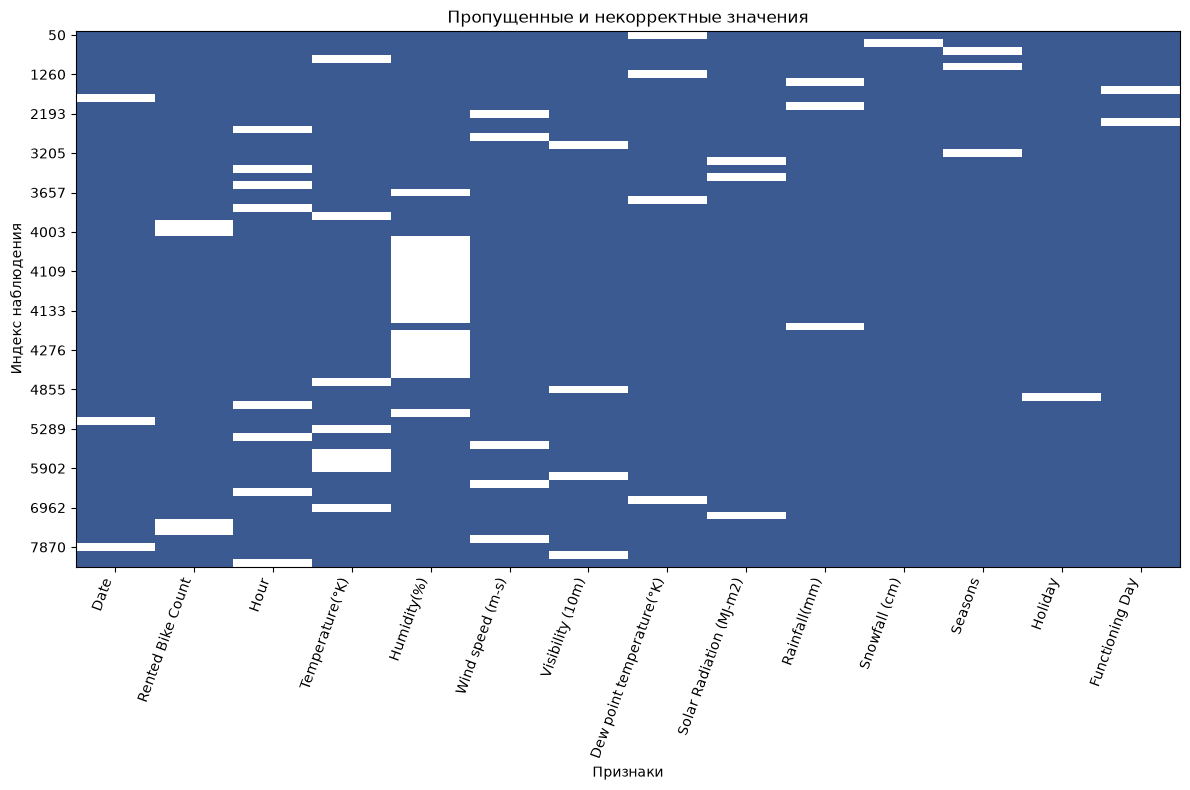

In [7]:
missing_rows = missing_mask.loc[missing_mask.any(axis=1)]
fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(missing_rows.to_numpy(), aspect='auto', interpolation='nearest',
          cmap=ListedColormap(['#3B5A92', 'white']))
ax.set_xticks(range(len(missing_rows.columns)))
ax.set_xticklabels(missing_rows.columns, rotation=70, ha='right')
step = 5
ax.set_yticks(range(0, len(missing_rows), step))
ax.set_yticklabels(missing_rows.index[::step])
ax.set_xlabel('Признаки')
ax.set_ylabel('Индекс наблюдения')
ax.set_title('Пропущенные и некорректные значения')
plt.tight_layout()
plt.show()

**Вывод.** После проверки допустимых диапазонов обнаружено 68 проблемных ячеек в 68 разных строках. Повреждения редки относительно общего объёма таблицы, поэтому целесообразно восстанавливать доступные значения без массового удаления наблюдений.

### 2.2. Восстановление даты и часа

In [8]:
assert df.index.equals(pd.RangeIndex(0, len(df)))
assert len(df) == 8760

timeline = pd.date_range('2017-12-01 00:00', periods=len(df), freq='h')
expected_dates = pd.Series(timeline.normalize(), index=df.index)
expected_hours = pd.Series(timeline.hour, index=df.index)

conflicting_dates = df['Date'].notna() & df['Date'].ne(expected_dates)
conflicting_hours = df['Hour'].notna() & df['Hour'].ne(expected_hours)
print('Противоречий среди дат:', int(conflicting_dates.sum()))
print('Противоречий среди часов:', int(conflicting_hours.sum()))
assert not conflicting_dates.any() and not conflicting_hours.any()

n_dates = int(df['Date'].isna().sum())
n_hours = int(df['Hour'].isna().sum())
df['Date'] = df['Date'].fillna(expected_dates)
df['Hour'] = df['Hour'].fillna(expected_hours).astype(int)
print('Восстановлено дат:', n_dates)
print('Восстановлено часов:', n_hours)

Противоречий среди дат: 0
Противоречий среди часов: 0
Восстановлено дат: 3
Восстановлено часов: 8


### 2.3. Интерполяция погодных показателей

In [9]:
weather_cols = [
    'Temperature(°K)', 'Humidity(%)', 'Wind speed (m-s)',
    'Visibility (10m)', 'Dew point temperature(°K)',
    'Solar Radiation (MJ-m2)'
]
weather_before = df[weather_cols].copy()
df[weather_cols] = df[weather_cols].interpolate(method='linear', limit_area='inside')

interpolated_mask = weather_before.isna() & df[weather_cols].notna()
interpolation_counts = interpolated_mask.sum().rename('Восстановлено интерполяцией')
display(interpolation_counts)

recovered_temperature = df.loc[interpolated_mask['Temperature(°K)'],
                               ['Date', 'Hour', 'Temperature(°K)']]
display(recovered_temperature.round(2))

Temperature(°K)               8
Humidity(%)                  19
Wind speed (m-s)              5
Visibility (10m)              4
Dew point temperature(°K)     4
Solar Radiation (MJ-m2)       3
Name: Восстановлено интерполяцией, dtype: int64

C:\Users\user\AppData\Local\Temp\ipykernel_11332\4016044099.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(recovered_temperature.round(2))


,Date,Hour,Temperature(°K)
892,2018-01-07,4,267.95
3947,2018-05-14,11,291.45
4660,2018-06-13,4,291.70
5289,2018-07-09,9,294.05
5611,2018-07-22,19,307.95
5825,2018-07-31,17,309.75
5902,2018-08-03,22,303.85
6962,2018-09-17,2,293.50


Интерполяция оценивает неизвестное значение по измерениям в соседние часы. Такой подход особенно обоснован для коротких пропусков температуры. Для последовательных пропусков влажности полученные значения являются приближёнными оценками, поскольку погодные условия могли изменяться внутри интервала.

### 2.4. Осадки и категориальные значения

In [10]:
precipitation_log = []
for col in ['Rainfall(mm)', 'Snowfall (cm)']:
    values = df[col]
    fill_mask = values.isna() & values.shift(1).eq(0) & values.shift(-1).eq(0)
    df.loc[fill_mask, col] = 0
    precipitation_log.append((col, int(fill_mask.sum())))
display(pd.DataFrame(precipitation_log, columns=['Признак', 'Восстановлено']))

,Признак,Восстановлено
0,Rainfall(mm),3
1,Snowfall (cm),1


In [11]:
category_log = []
for col in ['Seasons', 'Holiday', 'Functioning Day']:
    missing_days = df.loc[df[col].isna(), 'Date'].unique()
    category_counts = df.groupby('Date')[col].nunique(dropna=True)
    assert category_counts.reindex(missing_days).fillna(0).le(1).all()
    count = int(df[col].isna().sum())
    df[col] = df[col].fillna(df.groupby('Date')[col].transform('first'))
    category_log.append((col, count - int(df[col].isna().sum())))
display(pd.DataFrame(category_log, columns=['Признак', 'Восстановлено']))

,Признак,Восстановлено
0,Seasons,3
1,Holiday,1
2,Functioning Day,2


### 2.5. Итоговая таблица после обработки пропусков

In [12]:
rows_before = len(df)
df = df.dropna(subset=['Rented Bike Count']).copy()
assert not df.isna().any().any()
assert df['Rented Bike Count'].ge(0).all()
assert df['Rented Bike Count'].mod(1).eq(0).all()
df['Rented Bike Count'] = df['Rented Bike Count'].astype(int)

print('Удалено строк:', rows_before - len(df))
print('Размер таблицы:', df.shape)
print('Осталось пропусков:', int(df.isna().sum().sum()))
display(df.head())

Удалено строк: 4
Размер таблицы: (8756, 14)
Осталось пропусков: 0


,Date,Rented Bike Count,Hour,Temperature(°K),Humidity(%),Wind speed (m-s),Visibility (10m),Dew point temperature(°K),Solar Radiation (MJ-m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,2017-12-01,254,0,267.95,37.0,2.2,2000.0,255.55,0.0,0.0,0.0,Winter,No Holiday,Yes
1,2017-12-01,204,1,267.65,38.0,0.8,2000.0,255.55,0.0,0.0,0.0,Winter,No Holiday,Yes
2,2017-12-01,173,2,267.15,39.0,1.0,2000.0,255.45,0.0,0.0,0.0,Winter,No Holiday,Yes
3,2017-12-01,107,3,266.95,40.0,0.9,2000.0,255.55,0.0,0.0,0.0,Winter,No Holiday,Yes
4,2017-12-01,78,4,267.15,36.0,2.3,2000.0,254.55,0.0,0.0,0.0,Winter,No Holiday,Yes


**Вывод.** Обработка позволила сохранить 8756 из 8760 наблюдений (99,95%). Восстановлены 3 даты и 8 значений часа по проверенной временной последовательности, 8 температур и другие погодные значения с помощью интерполяции; отдельные пропуски осадков и категорий восстановлены по соседним наблюдениям. Четыре строки удалены из-за отсутствующего количества аренд. После обработки пропусков не осталось. Восстановленные погодные показатели следует рассматривать как оценки, а не как измеренные значения.

## 3. Преобразование категориальных признаков и даты

In [13]:
df['Date_month'] = df['Date'].dt.month
df['Date_dayofweek'] = df['Date'].dt.dayofweek

objColNames = ['Seasons', 'Holiday', 'Functioning Day']
prefixColNames = ['Seas', 'Hold', 'Fday']
df_dummies = pd.get_dummies(data=df[objColNames], prefix=prefixColNames, dtype=int)
display(df_dummies.head())

digitColName = [
    'Rented Bike Count', 'Hour', 'Temperature(°K)', 'Wind speed (m-s)',
    'Humidity(%)', 'Visibility (10m)', 'Dew point temperature(°K)',
    'Solar Radiation (MJ-m2)', 'Rainfall(mm)', 'Snowfall (cm)',
    'Date_month', 'Date_dayofweek'
]
df_digital = df[digitColName]
df_digPlus = pd.concat([df_digital, df_dummies], axis='columns')
display(df_digPlus.head())
print('Размер числовой таблицы:', df_digPlus.shape)

,Seas_Autumn,Seas_Spring,Seas_Summer,Seas_Winter,Hold_Holiday,Hold_No Holiday,Fday_No,Fday_Yes
0,0,0,0,1,0,1,0,1
1,0,0,0,1,0,1,0,1
2,0,0,0,1,0,1,0,1
3,0,0,0,1,0,1,0,1
4,0,0,0,1,0,1,0,1


,Rented Bike Count,Hour,Temperature(°K),Wind speed (m-s),Humidity(%),Visibility (10m),Dew point temperature(°K),Solar Radiation (MJ-m2),Rainfall(mm),Snowfall (cm),Date_month,Date_dayofweek,Seas_Autumn,Seas_Spring,Seas_Summer,Seas_Winter,Hold_Holiday,Hold_No Holiday,Fday_No,Fday_Yes
0,254,0,267.95,2.2,37.0,2000.0,255.55,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1
1,204,1,267.65,0.8,38.0,2000.0,255.55,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1
2,173,2,267.15,1.0,39.0,2000.0,255.45,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1
3,107,3,266.95,0.9,40.0,2000.0,255.55,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1
4,78,4,267.15,2.3,36.0,2000.0,254.55,0.0,0.0,0.0,12,4,0,0,0,1,0,1,0,1


Размер числовой таблицы: (8756, 20)


Категориальные признаки `Seasons`, `Holiday`, `Functioning Day` представлены бинарными индикаторами. Из даты получены числовые компоненты — месяц и номер дня недели. Полученная таблица содержит только числовые столбцы и подходит для расчёта коэффициентов корреляции и обучения регрессионных моделей.

### 3.1. Сохранение подготовленных данных

In [14]:
df_digPlus.to_csv('SeoulBikeData_prepared.csv', index=False, encoding='utf-8-sig')
print('Файл сохранён: SeoulBikeData_prepared.csv')

Файл сохранён: SeoulBikeData_prepared.csv


## 4. Выбор целевой переменной и объясняющих признаков

### 4.1. Корреляционная матрица

In [15]:
corr_df = df_digPlus.corr(method='pearson')
display(corr_df.round(3))

,Rented Bike Count,Hour,Temperature(°K),Wind speed (m-s),Humidity(%),Visibility (10m),Dew point temperature(°K),Solar Radiation (MJ-m2),Rainfall(mm),Snowfall (cm),Date_month,Date_dayofweek,Seas_Autumn,Seas_Spring,Seas_Summer,Seas_Winter,Hold_Holiday,Hold_No Holiday,Fday_No,Fday_Yes
Rented Bike Count,1.000,0.410,0.539,0.121,-0.204,0.199,0.380,0.262,-0.123,-0.142,0.133,-0.029,0.103,0.023,0.297,-0.425,-0.073,0.073,-0.204,0.204
Hour,0.410,1.000,0.124,0.285,-0.248,0.099,0.003,0.145,0.009,-0.021,-0.000,-0.000,-0.000,0.000,0.000,0.000,-0.001,0.001,-0.005,0.005
Temperature(°K),0.539,0.124,1.000,-0.036,0.162,0.035,0.913,0.354,0.050,-0.218,0.216,-0.003,0.060,0.008,0.666,-0.739,-0.057,0.057,0.050,-0.050
Wind speed (m-s),0.121,0.285,-0.036,1.000,-0.343,0.171,-0.177,0.332,-0.020,-0.004,-0.157,-0.021,-0.128,0.084,-0.064,0.109,0.022,-0.022,-0.005,0.005
Humidity(%),-0.204,-0.248,0.162,-0.343,1.000,-0.545,0.541,-0.468,0.238,0.108,0.139,-0.011,0.026,0.023,0.191,-0.243,-0.043,0.043,0.020,-0.020
Visibility (10m),0.199,0.099,0.035,0.171,-0.545,1.000,-0.176,0.149,-0.168,-0.122,0.065,-0.027,0.117,-0.187,0.062,0.008,0.031,-0.031,0.026,-0.026
Dew point temperature(°K),0.380,0.003,0.913,-0.177,0.541,-0.176,1.000,0.095,0.126,-0.151,0.243,-0.014,0.063,0.002,0.652,-0.722,-0.067,0.067,0.053,-0.053
Solar Radiation (MJ-m2),0.262,0.145,0.354,0.332,-0.468,0.149,0.095,1.000,-0.074,-0.072,-0.032,0.011,-0.032,0.080,0.129,-0.178,-0.006,0.006,0.008,-0.008
Rainfall(mm),-0.123,0.009,0.050,-0.020,0.238,-0.168,0.126,-0.074,1.000,0.008,0.012,-0.018,-0.013,0.018,0.054,-0.059,-0.014,0.014,-0.002,0.002
Snowfall (cm),-0.142,-0.021,-0.218,-0.004,0.108,-0.122,-0.151,-0.072,0.008,1.000,0.053,-0.012,-0.025,-0.100,-0.100,0.226,-0.012,0.012,-0.032,0.032


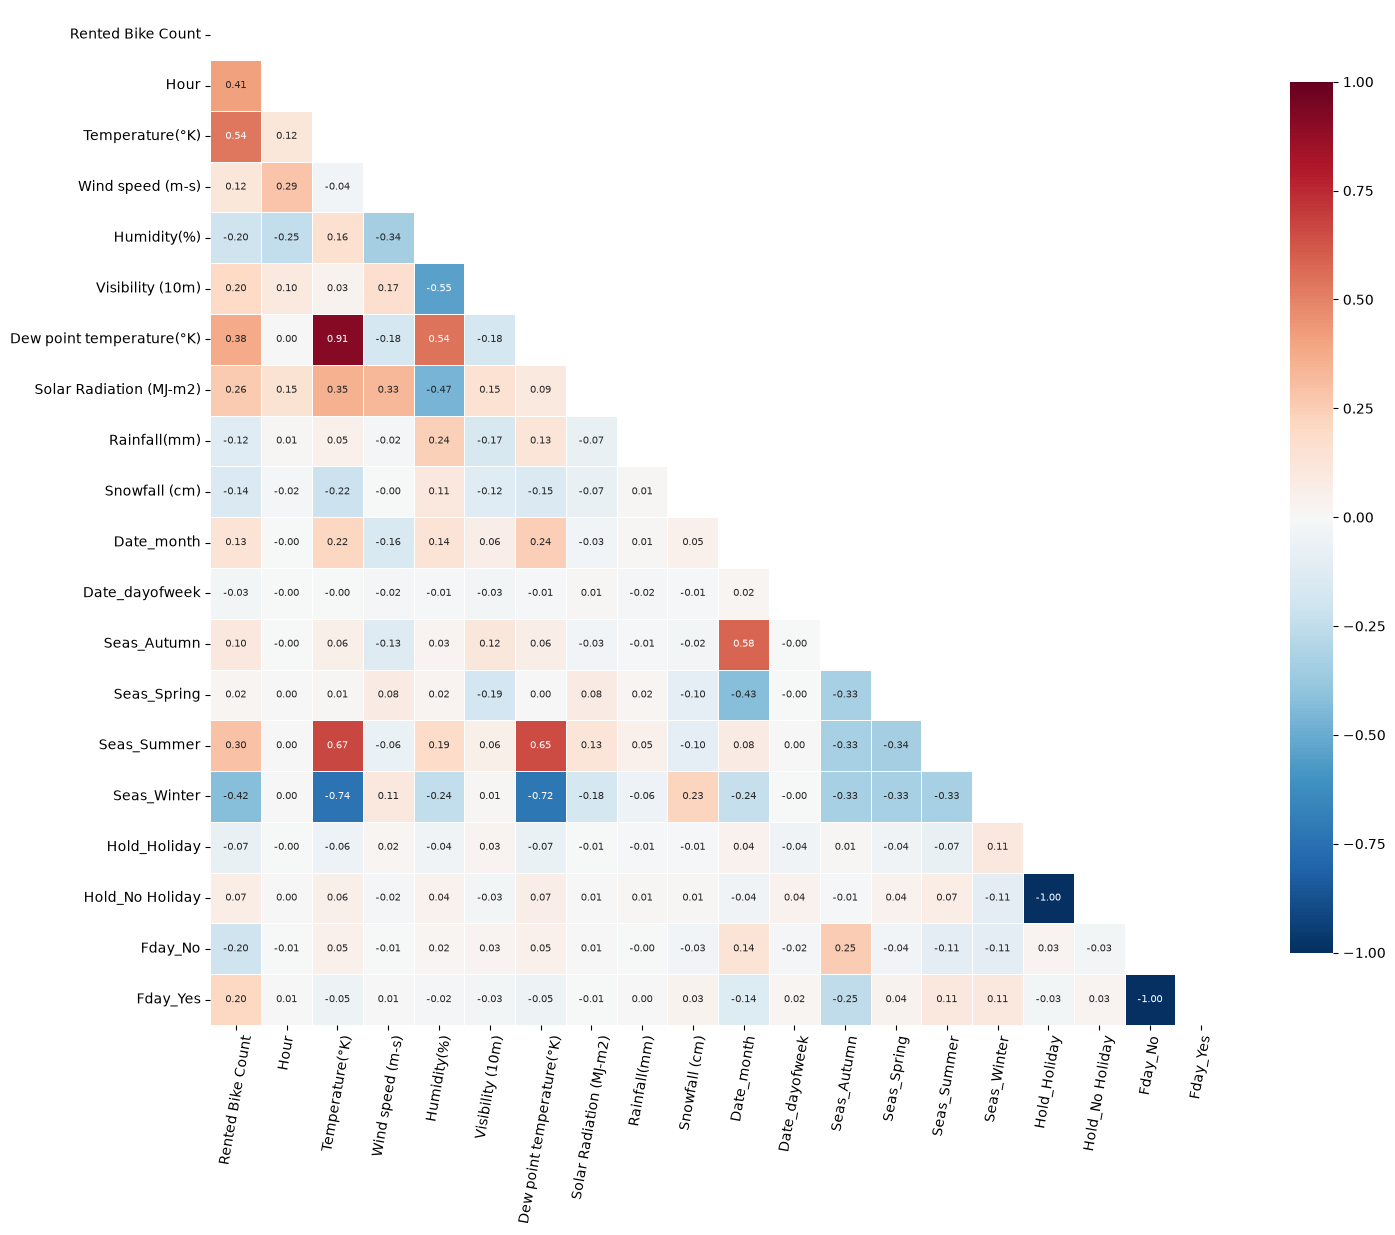

In [16]:
mask = np.zeros_like(corr_df, dtype=bool)
mask[np.triu_indices_from(mask)] = True
fig, ax = plt.subplots(figsize=(15, 14))
sns.heatmap(corr_df, vmin=-1, vmax=1, center=0,
            cmap='RdBu_r', annot=True, fmt='.2f',
            annot_kws={'size': 7}, mask=mask,
            square=True, linewidths=.5,
            cbar_kws={'shrink': .7}, ax=ax)
ax.tick_params(axis='x', labelrotation=80)
plt.tight_layout()
plt.show()

### 4.2. Корреляция с целевой переменной

In [17]:
target = 'Rented Bike Count'
correlations_to_target = corr_df[[target]].drop(index=target)
correlations_to_target['|r|'] = correlations_to_target[target].abs()
correlations_to_target = correlations_to_target.sort_values('|r|', ascending=False)
display(correlations_to_target.round(3))

,Rented Bike Count,|r|
Temperature(°K),0.539,0.539
Seas_Winter,-0.425,0.425
Hour,0.410,0.410
Dew point temperature(°K),0.380,0.380
Seas_Summer,0.297,0.297
Solar Radiation (MJ-m2),0.262,0.262
Fday_No,-0.204,0.204
Fday_Yes,0.204,0.204
Humidity(%),-0.204,0.204
Visibility (10m),0.199,0.199


### 4.3. Матрица смежности

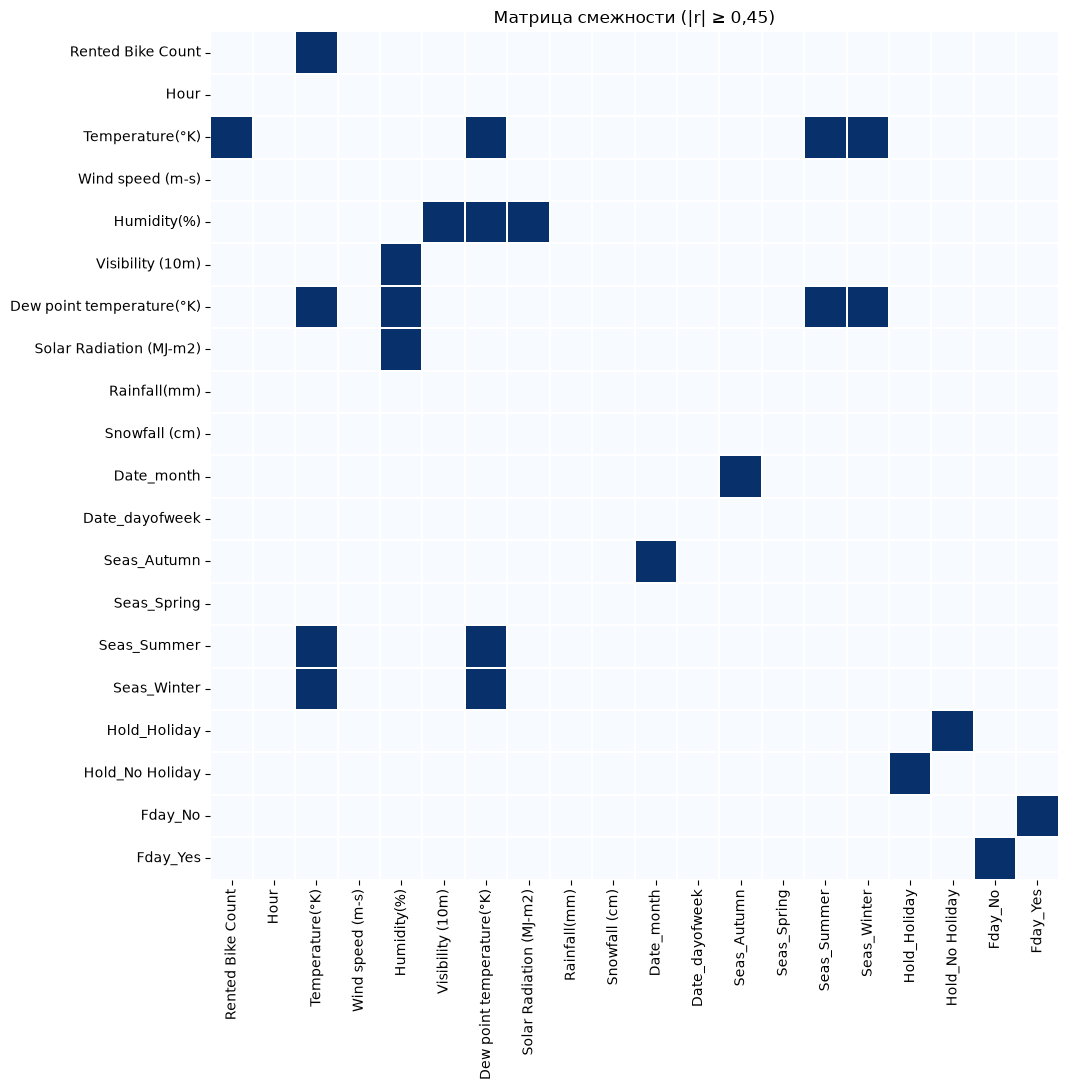

In [18]:
adjacency_threshold = 0.45
adjacency = (corr_df.abs() >= adjacency_threshold).astype(int).copy()
for i in range(len(adjacency)):
    adjacency.iat[i, i] = 0
fig, ax = plt.subplots(figsize=(12, 11))
sns.heatmap(adjacency, cmap='Blues', cbar=False, square=True, linewidths=.35, ax=ax)
ax.set_title('Матрица смежности (|r| ≥ 0,45)')
plt.tight_layout()
plt.show()

### 4.4. Диаграммы рассеяния

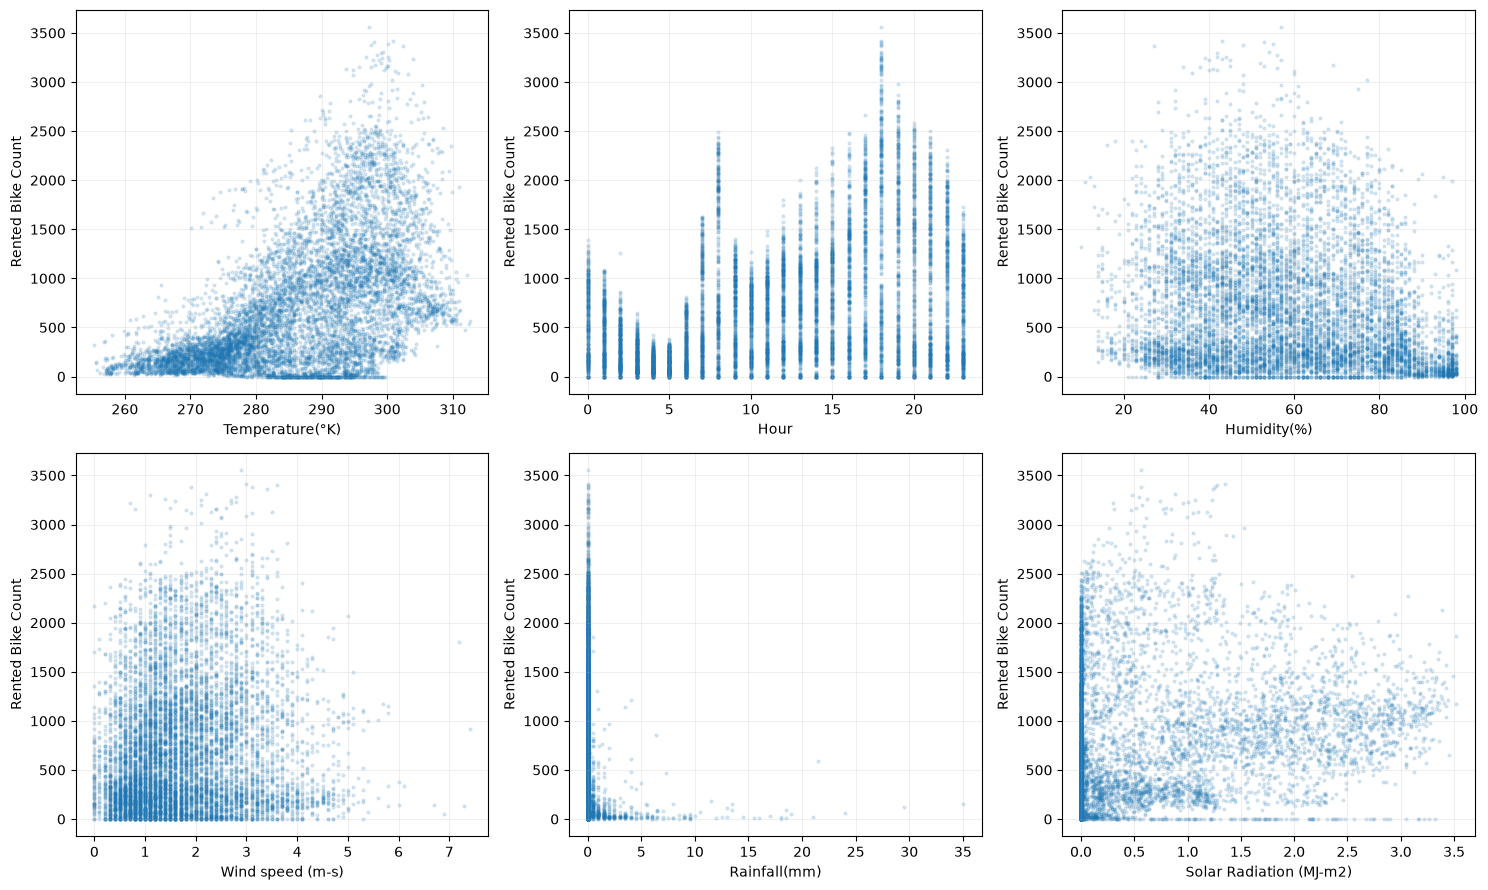

In [19]:
candidate_features = [
    'Temperature(°K)', 'Hour', 'Humidity(%)',
    'Wind speed (m-s)', 'Rainfall(mm)', 'Solar Radiation (MJ-m2)'
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, feature in zip(axes.flat, candidate_features):
    ax.scatter(df_digPlus[feature], df_digPlus[target], s=4, alpha=.15)
    ax.set_xlabel(feature)
    ax.set_ylabel(target)
    ax.grid(alpha=.2)
plt.tight_layout()
plt.show()

**Вывод.** Целевая переменная — количество арендованных велосипедов `Rented Bike Count`. Наиболее заметные линейные связи обнаружены с температурой воздуха (r = 0,539), часом суток (r = 0,410) и температурой точки росы (r = 0,380). Для зимнего сезона наблюдается отрицательная корреляция (r = −0,425). Температура и точка росы сильно коррелируют друг с другом (r = 0,913), поэтому одновременное использование этих признаков может затруднить интерпретацию коэффициентов регрессии. Диаграмма зависимости количества аренд от часа суток показывает неравномерность спроса и выраженные пики, которые не описываются одной прямой. Для сравнения выбраны одномерная модель по температуре и две многомерные модели с различными наборами погодных и календарных признаков.

## 5. Поиск и обработка выбросов

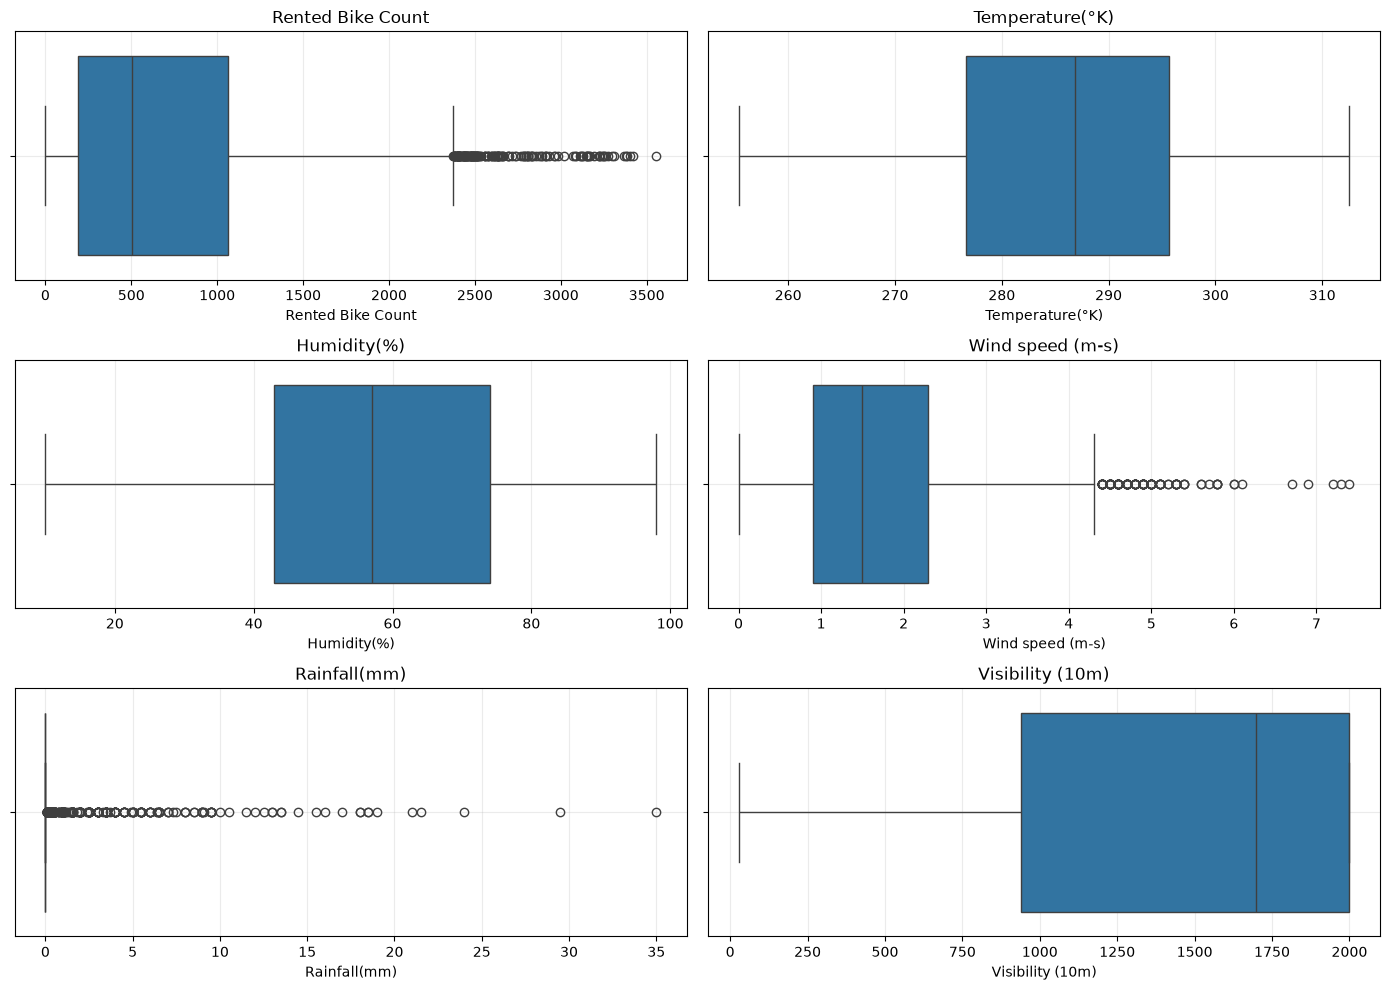

In [20]:
inspect_features = [
    'Rented Bike Count', 'Temperature(°K)', 'Humidity(%)',
    'Wind speed (m-s)', 'Rainfall(mm)', 'Visibility (10m)'
]
fig, axes = plt.subplots(3, 2, figsize=(14, 10))
for ax, col in zip(axes.flat, inspect_features):
    sns.boxplot(x=df_digPlus[col], ax=ax)
    ax.set_title(col)
    ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

In [21]:
outlier_info = []
for col in inspect_features:
    q1, q3 = df_digPlus[col].quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = (~df_digPlus[col].between(lower, upper)).sum()
    outlier_info.append((col, lower, upper, int(count)))
display(pd.DataFrame(outlier_info, columns=[
    'Признак', 'Нижняя граница', 'Верхняя граница', 'За границами'
]).round(3))

,Признак,Нижняя граница,Верхняя граница,За границами
0,Rented Bike Count,-1118.500,2373.500,159
1,Temperature(°K),248.088,324.187,0
2,Humidity(%),-3.500,120.500,0
3,Wind speed (m-s),-1.200,4.400,161
4,Rainfall(mm),0.000,0.000,528
5,Visibility (10m),-650.000,3590.000,0


**Вывод.** Метод межквартильного размаха выявил 159 высоких значений спроса, 161 значение скорости ветра и 528 ненулевых показаний осадков. Для дождя оба квартиля равны нулю, поэтому любое положительное количество осадков определяется как статистический выброс. Эти значения могут соответствовать реальным погодным условиям и часам повышенного спроса. После проверки физических ограничений оснований для их удаления не установлено; дальнейшее моделирование проводится на полном очищенном наборе из 8756 строк.

До фильтрации: (8756, 20)
После фильтрации: (8756, 20)


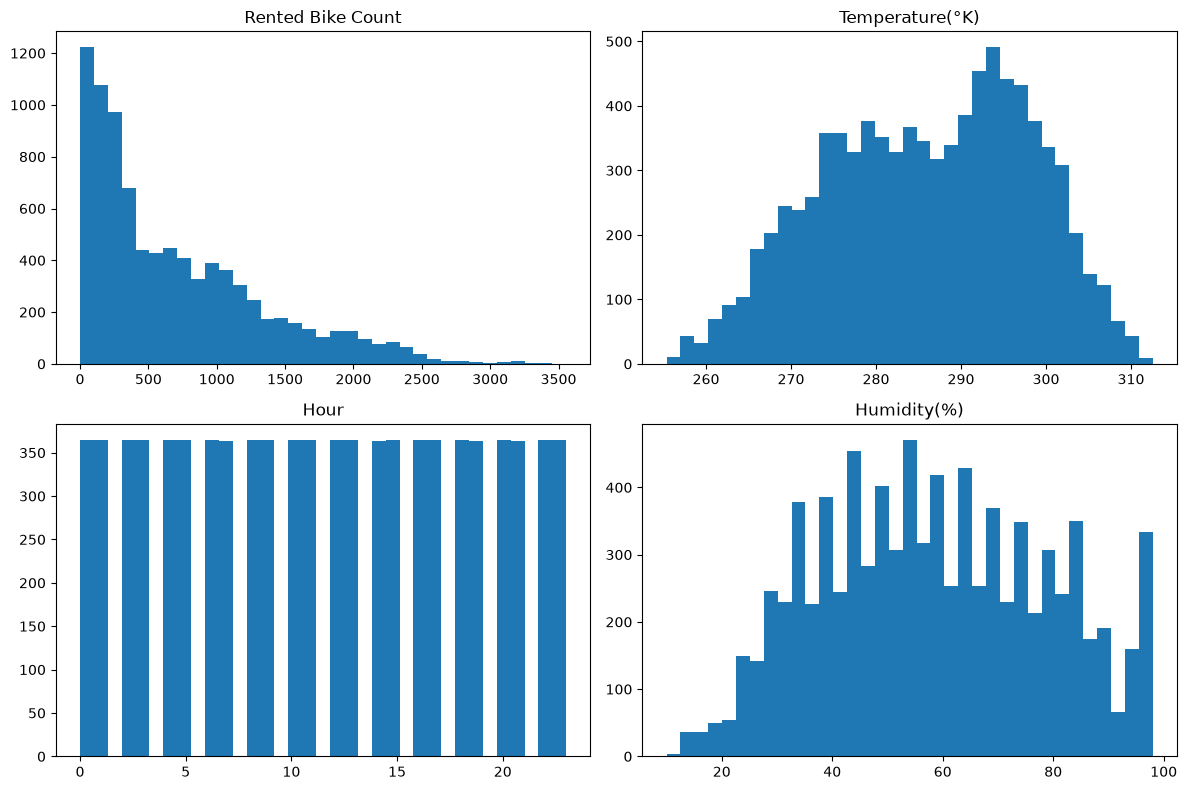

In [22]:
df_digPlusFiltred = df_digPlus.copy()
print('До фильтрации:', df_digPlus.shape)
print('После фильтрации:', df_digPlusFiltred.shape)
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, ['Rented Bike Count', 'Temperature(°K)', 'Hour', 'Humidity(%)']):
    ax.hist(df_digPlusFiltred[col], bins=35)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## 6. Формирование обучающей и проверочной выборок

In [23]:
features_m1 = ['Temperature(°K)']
features_m2 = ['Temperature(°K)', 'Humidity(%)', 'Wind speed (m-s)', 'Rainfall(mm)']
features_m3 = ['Temperature(°K)', 'Hour', 'Humidity(%)', 'Rainfall(mm)',
               'Seas_Winter', 'Seas_Summer', 'Fday_Yes']
features = list(dict.fromkeys(features_m1 + features_m2 + features_m3))
valid_size = 0.3
rand_seed = 8

x_train, x_test, y_train, y_test = train_test_split(
    df_digPlusFiltred[features],
    df_digPlusFiltred[target],
    test_size=valid_size,
    random_state=rand_seed,
    shuffle=True
)
print('Обучающая выборка:', x_train.shape, y_train.shape)
print('Проверочная выборка:', x_test.shape, y_test.shape)
display(x_test.head(3))
display(y_test.head(3))

Обучающая выборка: (6129, 8) (6129,)
Проверочная выборка: (2627, 8) (2627,)


,Temperature(°K),Humidity(%),Wind speed (m-s),Rainfall(mm),Hour,Seas_Winter,Seas_Summer,Fday_Yes
1737,264.55,28.0,1.5,0.0,9,1,0,1
7350,284.55,84.0,0.3,0.0,6,0,0,1
5769,303.75,54.0,1.7,0.0,9,0,1,1


1737    126
7350    278
5769    519
Name: Rented Bike Count, dtype: int64

Для проверки выделено 30% наблюдений, 70% использованы для обучения. Разделение выполнено с фиксированным состоянием генератора случайных чисел `random_state=8`, что обеспечивает воспроизводимость сравнения. Все три модели оцениваются на одной и той же проверочной выборке.

## 7. Построение линейных регрессионных моделей

### 7.1. Модель M1. Одномерная регрессия по температуре

In [24]:
model_m1 = linear_model.LinearRegression()
model_m1.fit(x_train[features_m1], y_train)
y_pred_m1 = model_m1.predict(x_test[features_m1])
print('Коэффициент:', model_m1.coef_[0])
print('Свободный член:', model_m1.intercept_)
print(f'y = {model_m1.coef_[0]:.3f} × Temperature + ({model_m1.intercept_:.3f})')

Коэффициент: 29.48132524266673
Свободный член: -7723.171341991253
y = 29.481 × Temperature + (-7723.171)


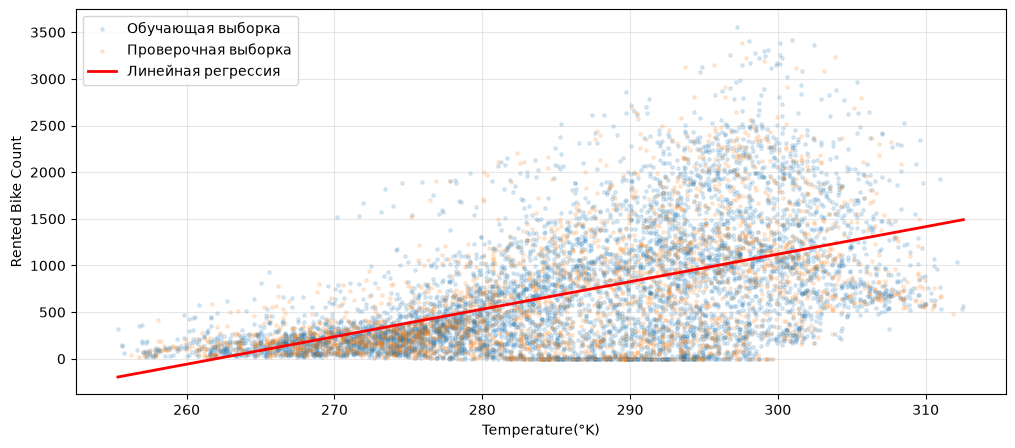

In [25]:
plt.figure(figsize=(12, 5))
plt.scatter(x_train[features_m1[0]], y_train, alpha=.15, s=6, label='Обучающая выборка')
plt.scatter(x_test[features_m1[0]], y_test, alpha=.15, s=6, label='Проверочная выборка')
x_line = np.linspace(df_digPlusFiltred[features_m1[0]].min(),
                     df_digPlusFiltred[features_m1[0]].max(), 100)
plt.plot(x_line, model_m1.coef_[0] * x_line + model_m1.intercept_,
         color='red', linewidth=2, label='Линейная регрессия')
plt.xlabel(features_m1[0])
plt.ylabel(target)
plt.legend()
plt.grid(alpha=.3)
plt.show()

In [26]:
mae_m1 = metrics.mean_absolute_error(y_test, y_pred_m1)
mse_m1 = metrics.mean_squared_error(y_test, y_pred_m1)
rmse_m1 = np.sqrt(mse_m1)
r2_m1 = metrics.r2_score(y_test, y_pred_m1)
print(f'MAE: {mae_m1:.3f}; MSE: {mse_m1:.3f}; RMSE: {rmse_m1:.3f}; R²: {r2_m1:.4f}')

MAE: 394.334; MSE: 280047.758; RMSE: 529.195; R²: 0.2910


### 7.2. Модель M2. Многомерная регрессия по погодным признакам

In [27]:
model_m2 = linear_model.LinearRegression()
model_m2.fit(x_train[features_m2], y_train)
y_pred_m2 = model_m2.predict(x_test[features_m2])
print('Свободный член:', model_m2.intercept_)
display(pd.DataFrame({'Признак': features_m2, 'Коэффициент': model_m2.coef_}))
print('y =', ' + '.join(f'({k:.3f}) × {col}' for col, k in zip(features_m2, model_m2.coef_)), f'+ ({model_m2.intercept_:.3f})')

Свободный член: -8059.306485328464


,Признак,Коэффициент
0,Temperature(°K),32.122524
1,Humidity(%),-8.236585
2,Wind speed (m-s),39.240862
3,Rainfall(mm),-52.819736


y = (32.123) × Temperature(°K) + (-8.237) × Humidity(%) + (39.241) × Wind speed (m-s) + (-52.820) × Rainfall(mm) + (-8059.306)


In [28]:
mae_m2 = metrics.mean_absolute_error(y_test, y_pred_m2)
mse_m2 = metrics.mean_squared_error(y_test, y_pred_m2)
rmse_m2 = np.sqrt(mse_m2)
r2_m2 = metrics.r2_score(y_test, y_pred_m2)
print(f'MAE: {mae_m2:.3f}; MSE: {mse_m2:.3f}; RMSE: {rmse_m2:.3f}; R²: {r2_m2:.4f}')

MAE: 361.636; MSE: 243492.943; RMSE: 493.450; R²: 0.3836


### 7.3. Модель M3. Многомерная регрессия по погодным и календарным признакам

In [29]:
model_m3 = linear_model.LinearRegression()
model_m3.fit(x_train[features_m3], y_train)
y_pred_m3 = model_m3.predict(x_test[features_m3])
print('Свободный член:', model_m3.intercept_)
display(pd.DataFrame({'Признак': features_m3, 'Коэффициент': model_m3.coef_}))
print('y =', ' + '.join(f'({k:.3f}) × {col}' for col, k in zip(features_m3, model_m3.coef_)), f'+ ({model_m3.intercept_:.3f})')

Свободный член: -6673.334936661414


,Признак,Коэффициент
0,Temperature(°K),23.385752
1,Hour,28.784019
2,Humidity(%),-6.835981
3,Rainfall(mm),-60.599244
4,Seas_Winter,-312.824033
5,Seas_Summer,-54.071582
6,Fday_Yes,888.433374


y = (23.386) × Temperature(°K) + (28.784) × Hour + (-6.836) × Humidity(%) + (-60.599) × Rainfall(mm) + (-312.824) × Seas_Winter + (-54.072) × Seas_Summer + (888.433) × Fday_Yes + (-6673.335)


In [30]:
mae_m3 = metrics.mean_absolute_error(y_test, y_pred_m3)
mse_m3 = metrics.mean_squared_error(y_test, y_pred_m3)
rmse_m3 = np.sqrt(mse_m3)
r2_m3 = metrics.r2_score(y_test, y_pred_m3)
print(f'MAE: {mae_m3:.3f}; MSE: {mse_m3:.3f}; RMSE: {rmse_m3:.3f}; R²: {r2_m3:.4f}')

MAE: 324.603; MSE: 185064.832; RMSE: 430.192; R²: 0.5315


## 8. Сравнение результатов моделирования

In [31]:
model_comparison = pd.DataFrame({
    'Модель': ['M1', 'M2', 'M3'],
    'Число признаков': [len(features_m1), len(features_m2), len(features_m3)],
    'MAE': [mae_m1, mae_m2, mae_m3],
    'MSE': [mse_m1, mse_m2, mse_m3],
    'RMSE': [rmse_m1, rmse_m2, rmse_m3],
    'R²': [r2_m1, r2_m2, r2_m3]
})
display(model_comparison.round(4))

sizes = pd.DataFrame({
    'Этап': ['Загрузка данных', 'Обработка пропусков', 'Анализ выбросов'],
    'Строк': [len(before_cleaning), len(df), len(df_digPlusFiltred)],
    'Столбцов': [before_cleaning.shape[1], df.shape[1], df_digPlusFiltred.shape[1]]
})
display(sizes)

,Модель,Число признаков,MAE,MSE,RMSE,R²
0,M1,1,394.3336,280047.7583,529.1954,0.2910
1,M2,4,361.6359,243492.9433,493.4500,0.3836
2,M3,7,324.6027,185064.8323,430.1916,0.5315


,Этап,Строк,Столбцов
0,Загрузка данных,8760,14
1,Обработка пропусков,8756,16
2,Анализ выбросов,8756,20


## 9. Учёт затрат времени по этапам CRISP-DM

В таблицу необходимо внести фактическое время выполнения этапов работы в минутах.

,Этап,"Время, мин"
0,Бизнес-анализ,120
1,Анализ данных,30
2,Подготовка данных,240
3,Моделирование (обучение),180
4,Моделирование (оценка),90
5,Оценка решения и внедрение,90


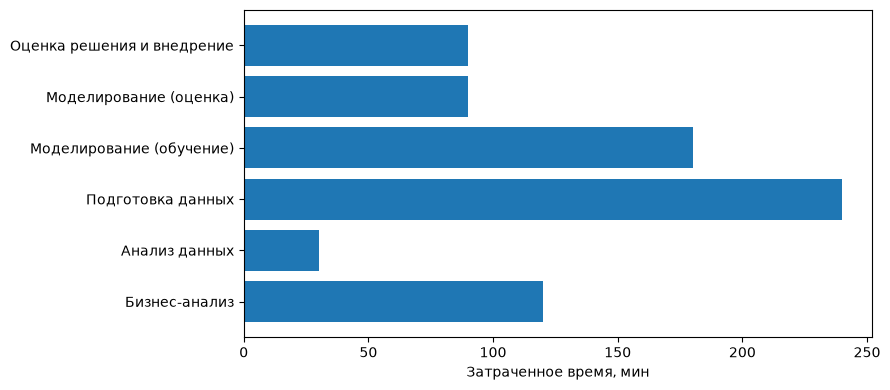

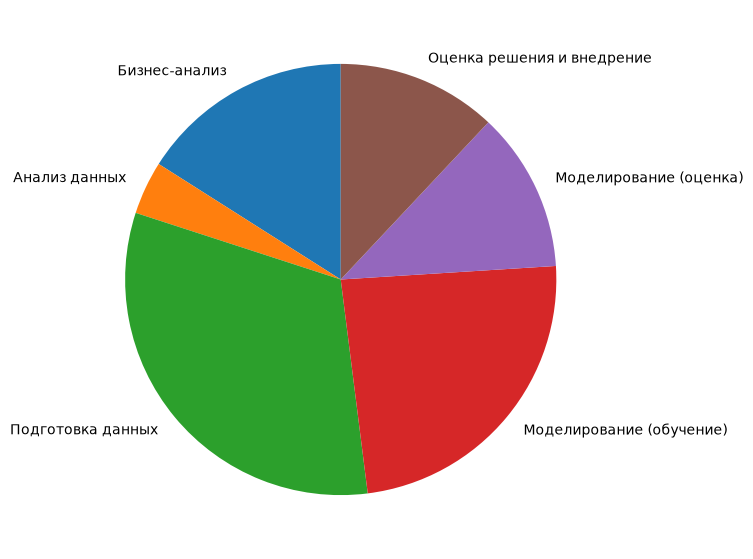

In [32]:
time_minutes = {
    'Бизнес-анализ': 120,
    'Анализ данных': 30,
    'Подготовка данных': 240,
    'Моделирование (обучение)': 180,
    'Моделирование (оценка)': 90,
    'Оценка решения и внедрение': 90,
}
dfSpendTimeLab1 = pd.DataFrame({
    'Этап': list(time_minutes.keys()),
    'Время, мин': list(time_minutes.values())
})
display(dfSpendTimeLab1)
if dfSpendTimeLab1['Время, мин'].notna().all():
    plt.figure(figsize=(9, 4))
    plt.barh(dfSpendTimeLab1['Этап'], dfSpendTimeLab1['Время, мин'])
    plt.xlabel('Затраченное время, мин')
    plt.tight_layout()
    plt.show()
    plt.figure(figsize=(7, 7))
    plt.pie(dfSpendTimeLab1['Время, мин'], labels=dfSpendTimeLab1['Этап'], startangle=90)
    plt.show()

# 10. Выводы по работе

В ходе лабораторной работы выполнены первичный анализ и очистка данных о почасовом прокате велосипедов в Сеуле, изучены взаимосвязи признаков, построены три линейные регрессионные модели, рассчитаны оценки их точности.

**Исходные данные и предобработка.** Таблица содержала 8760 записей и 14 столбцов. После преобразования типов было обнаружено 36 пропусков, а проверка допустимых диапазонов выявила ещё 32 некорректных значения. Дата и час восстановлены по непрерывной временной последовательности, погодные показатели — преимущественно линейной интерполяцией, пропуски осадков и категориальных признаков — по согласованным соседним наблюдениям. Четыре записи с неизвестным числом аренд исключены. Сохранено 8756 записей (99,95%).

**Выбор признаков.** Наиболее заметная линейная связь числа аренд обнаружена с температурой воздуха (r = 0,539), часом суток (r = 0,410) и температурой точки росы (r = 0,380). Корреляция температуры и точки росы (r = 0,913) указывает на сильную взаимосвязь предикторов. Зависимость спроса от часа суток имеет пики, поэтому недостаточно хорошо описывается прямой линией.

**Выбросы.** По критерию межквартильного размаха обнаружены 159 высоких значений числа аренд, 161 необычное значение скорости ветра и 528 ненулевых значений осадков. Поскольку они не являются установленными ошибками измерения, удаление этих наблюдений не проводилось. Для количества осадков IQR равен нулю, из-за чего любое ненулевое значение оказывается за формальными границами.

**Сравнение моделей.**

| Модель | MAE | RMSE | R² |
|---|---:|---:|---:|
| M1: температура воздуха | 394,334 | 529,195 | 0,2910 |
| M2: погодные признаки | 361,636 | 493,450 | 0,3836 |
| M3: погодные и календарные признаки | 324,603 | 430,192 | 0,5315 |

Наибольший коэффициент детерминации получила модель **M3**. Её R² выше, чем у M1, на 0,2405; RMSE ниже приблизительно на 99 аренд, или на 18,7%. Включение календарных и категориальных факторов позволило улучшить качество линейной регрессии на выбранной проверочной выборке. При этом R² = 0,5315 показывает, что линейная модель объясняет лишь часть изменчивости спроса.

**Обобщение.** Более подробная подготовка исходных данных позволила сохранить почти все наблюдения. Сопоставление трёх моделей показало пользу комбинирования погодных и временных факторов. Результаты получены при случайном разделении наблюдений; для оценки прогноза будущих периодов дополнительно потребовалась бы проверка на более позднем временном интервале.